# Particle filtering

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from rainfall import *
from particle_filter import *

In [3]:
data = load_data("./data/rainfall.pt")
theta = data["theta"]
x = data["x"]
stations = data["stations"]
y = data["y"]
z = data["z"]
meta = data["meta"]

In [4]:
torch.manual_seed(548)
particles, log_weights, esses = filter(stations, z, n=1000, T=10)

In [5]:
esses

[tensor(1.),
 tensor(1.0005),
 tensor(1.),
 tensor(1.),
 tensor(1.0001),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.)]

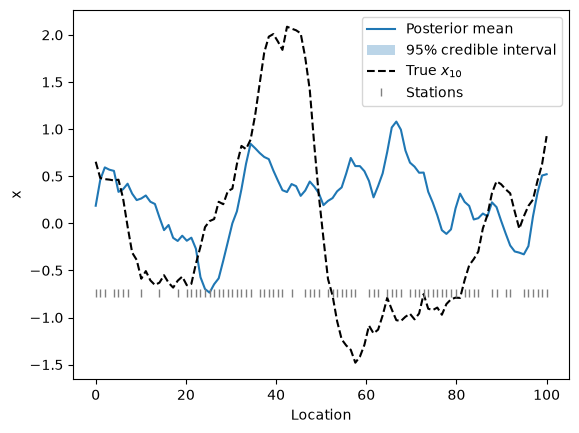

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def weighted_quantiles(samples, weights, qs):
    """ Weighted quantiles of each column of samples (N, g), shape (len(qs), g) """
    order = np.argsort(samples, axis=0)
    s = np.take_along_axis(samples, order, axis=0)
    w = weights[order]
    cdf = np.cumsum(w, axis=0) - w/2 # midpoint cdf, so a single sample is not a step
    return np.stack([np.interp(qs, cdf[:, j], s[:, j]) for j in range(s.shape[1])], axis=1)

t = 10
samples = torch.stack([p[1] for p in particles]).numpy() # (n, grid)
weights = log_weights.exp().numpy()
location = np.linspace(0, 100, samples.shape[1]) # grid used by draw_prior_state
post_mean = weights @ samples
lower, upper = weighted_quantiles(samples, weights, [0.025, 0.975])

plt.plot(location, post_mean, label="Posterior mean")
plt.fill_between(location, lower, upper, alpha=0.3, label="95% credible interval")
plt.plot(location, x[t].numpy(), "k--", label=rf"True $x_{{{t}}}$")
plt.plot(location[stations], np.full(len(stations), lower.min()), "|", color="gray",
         label="Stations")
plt.xlabel("Location")
plt.ylabel("x")
plt.legend()
plt.show()